In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

dataset_paths = {
    "Boralasgamuwa": "/content/daily_waste_output_Boralasgamuwa.csv",
    "Moratuwa": "/content/daily_waste_output_Moratuwa.csv",
    "Dehiwala": "/content/daily_waste_output_Dehiwala.csv",
    "Ballarat": "/content/daily_waste_output_Ballarat.csv",

}

datasets = {}

for name, path in dataset_paths.items():
    df = pd.read_csv(path)

    # Convert dates to UTC, then remove timezone information
    df["ticket_date"] = (
        pd.to_datetime(df["ticket_date"], errors="coerce", utc=True)
        .dt.tz_convert(None)
        .dt.normalize()
    )

    df["net_weight_kg"] = pd.to_numeric(
        df["net_weight_kg"], errors="coerce"
    )

    # Remove rows with invalid dates
    df = df.dropna(subset=["ticket_date"])

    df = df.sort_values("ticket_date").reset_index(drop=True)

    datasets[name] = df

    print(f"\n{name}")
    print("Rows:", len(df))
    print("Date range:",
          df["ticket_date"].min(),
          "to",
          df["ticket_date"].max())
    print("Date type:", df["ticket_date"].dtype)


Boralasgamuwa
Rows: 2557
Date range: 2012-01-01 00:00:00 to 2018-12-31 00:00:00
Date type: datetime64[ns]

Moratuwa
Rows: 1461
Date range: 2015-01-01 00:00:00 to 2018-12-31 00:00:00
Date type: datetime64[ns]

Dehiwala
Rows: 1461
Date range: 2012-01-01 00:00:00 to 2015-12-31 00:00:00
Date type: datetime64[ns]

Ballarat
Rows: 4017
Date range: 2001-01-01 00:00:00 to 2011-12-31 00:00:00
Date type: datetime64[ns]


In [2]:
statistics = []

for name, df in datasets.items():
    waste = df["net_weight_kg"].dropna()

    statistics.append({
        "Dataset": name,
        "Count": waste.count(),
        "Mean": waste.mean(),
        "Median": waste.median(),
        "Standard Deviation": waste.std(),
        "Minimum": waste.min(),
        "Q1 (25%)": waste.quantile(0.25),
        "Q3 (75%)": waste.quantile(0.75),
        "Maximum": waste.max(),
        "Skewness": waste.skew(),
        "Kurtosis": waste.kurtosis()
    })

statistics_df = pd.DataFrame(statistics).set_index("Dataset")

display(statistics_df.round(2))

,Count,Mean,Median,Standard Deviation,Minimum,Q1 (25%),Q3 (75%),Maximum,Skewness,Kurtosis
Dataset,,,,,,,,,,
Boralasgamuwa,2557,27116.62,28060.0,8857.16,0.0,22270.0,32780.0,58250.0,-0.39,0.24
Moratuwa,1461,88231.97,85830.0,25047.98,0.0,73740.0,101810.0,221570.0,0.25,2.35
Dehiwala,1461,142380.93,148650.0,33244.19,21050.0,122630.0,164260.0,240950.0,-0.65,0.54
Ballarat,4017,47957.61,60720.0,31507.64,0.0,0.0,69920.0,105460.0,-0.70,-1.14


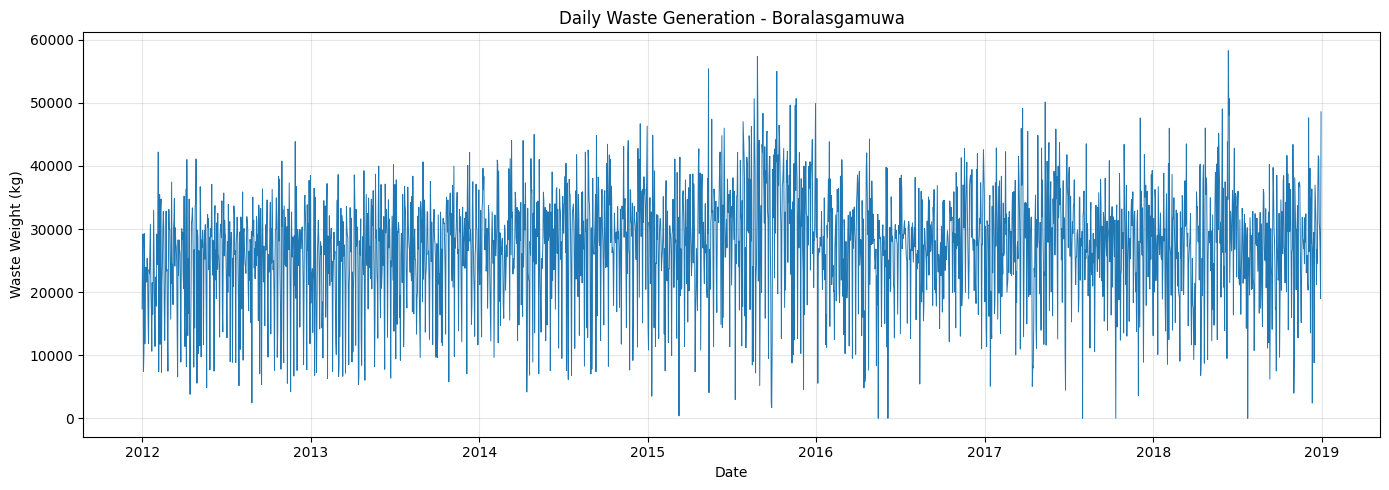

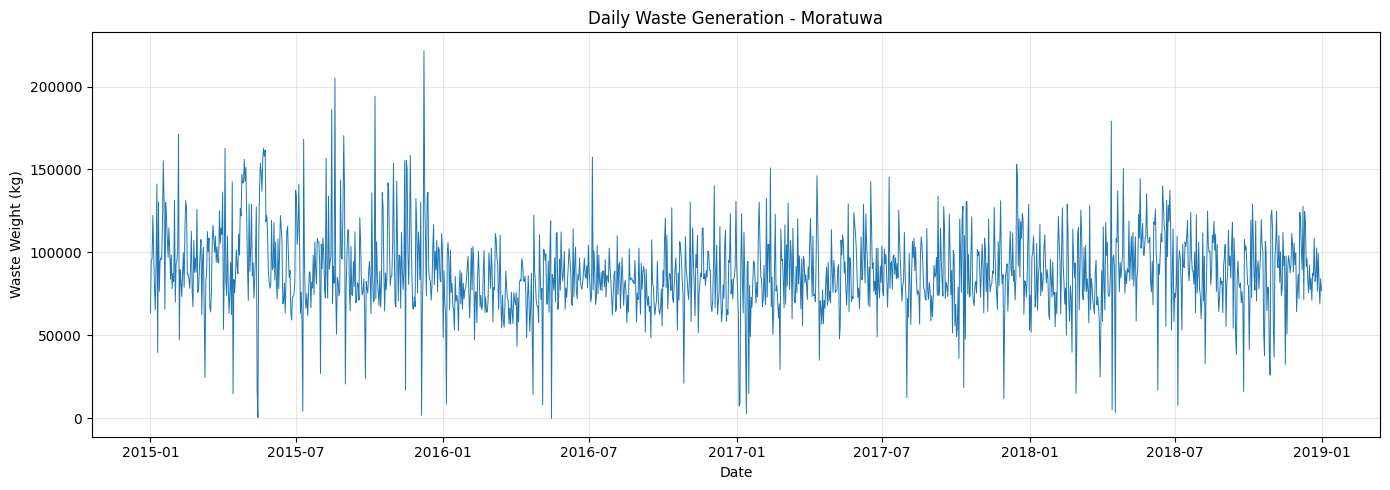

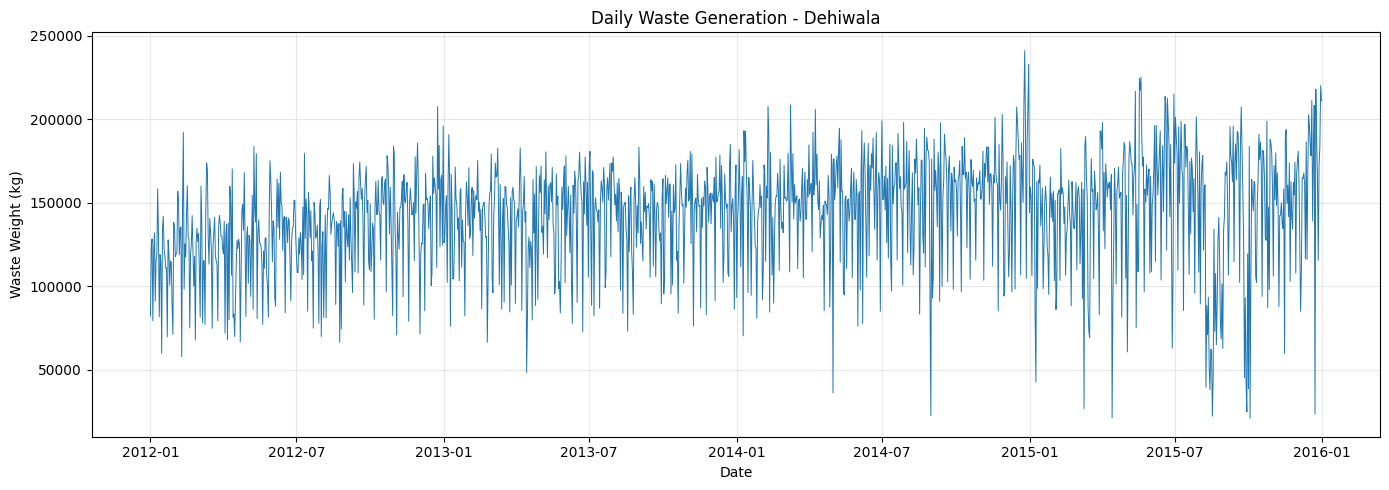

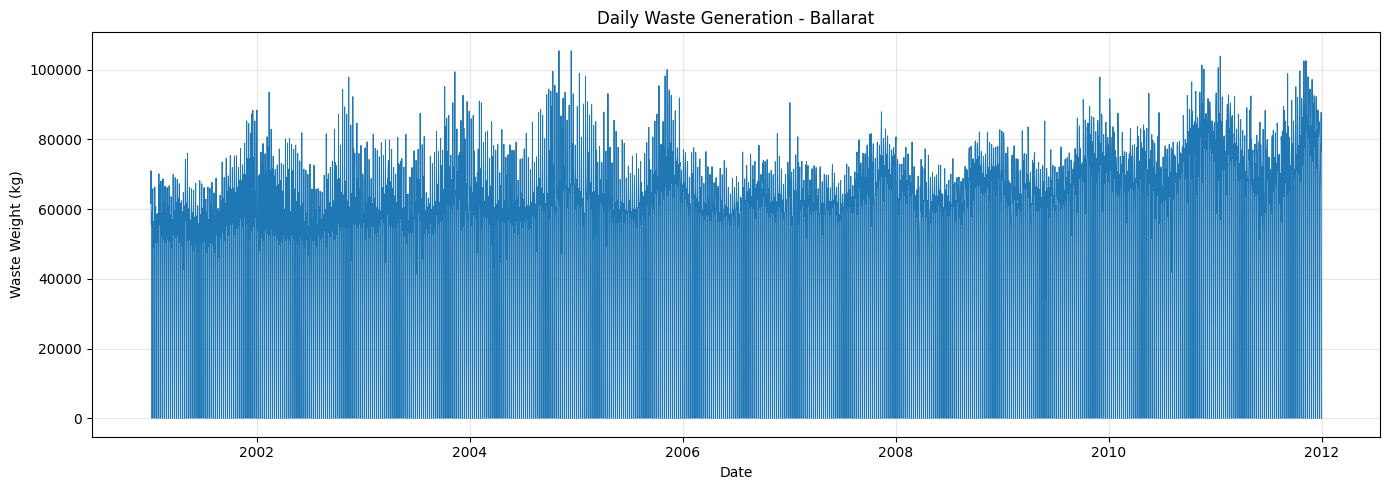

In [3]:
for name, df in datasets.items():
    plt.figure(figsize=(14, 5))

    plt.plot(
        df["ticket_date"],
        df["net_weight_kg"],
        linewidth=0.7
    )

    plt.title(f"Daily Waste Generation - {name}")
    plt.xlabel("Date")
    plt.ylabel("Waste Weight (kg)")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

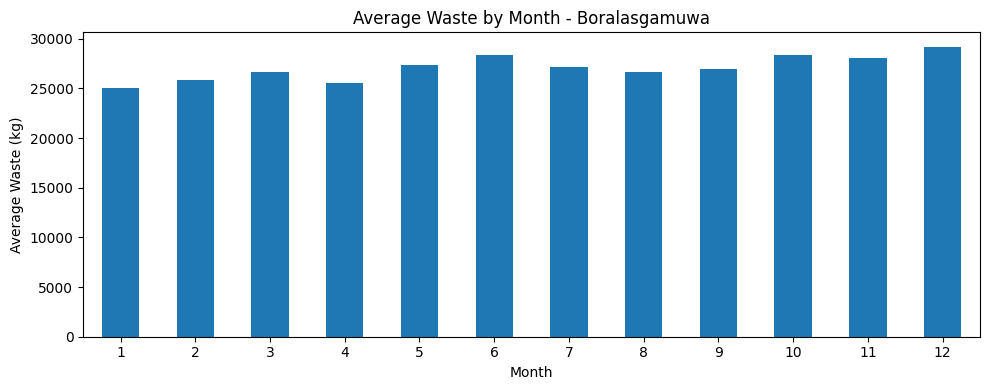

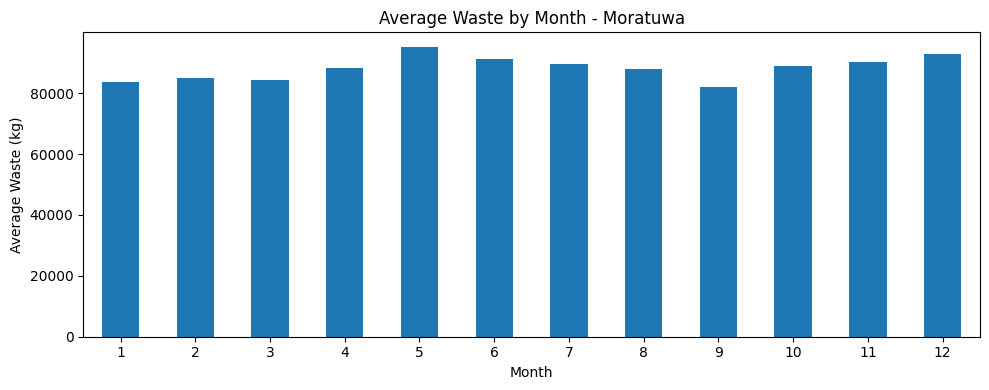

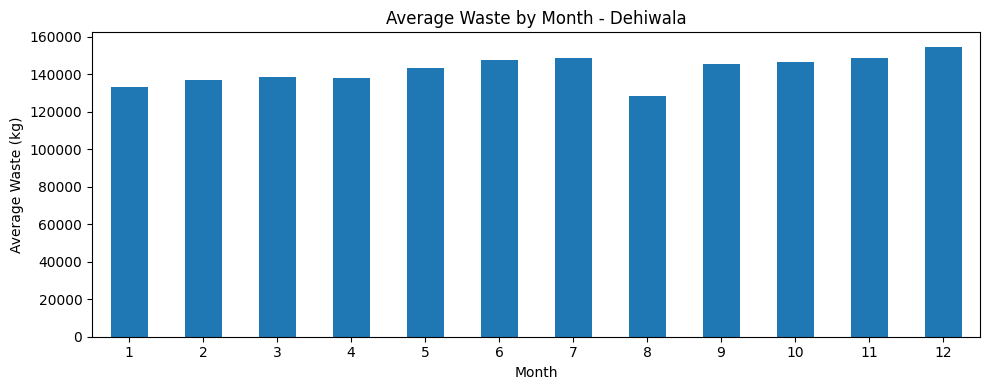

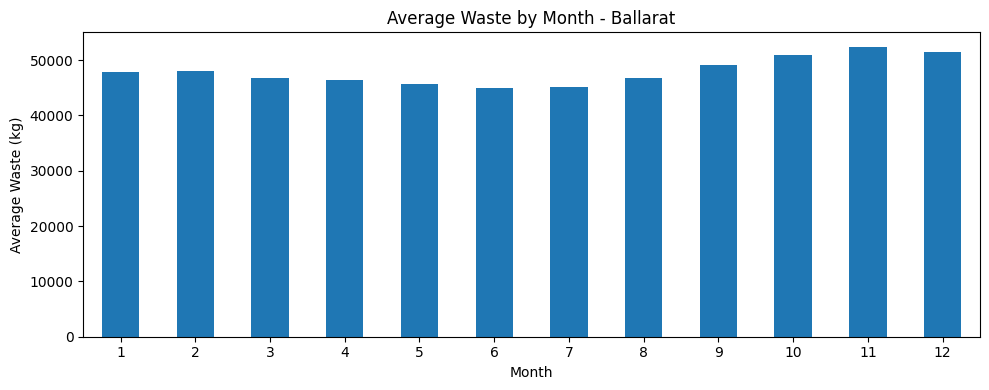

In [4]:
for name, df in datasets.items():
    temp = df.copy()
    temp["Month"] = temp["ticket_date"].dt.month

    monthly = temp.groupby("Month")["net_weight_kg"].mean()

    monthly.plot(kind="bar", figsize=(10, 4))
    plt.title(f"Average Waste by Month - {name}")
    plt.xlabel("Month")
    plt.ylabel("Average Waste (kg)")
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

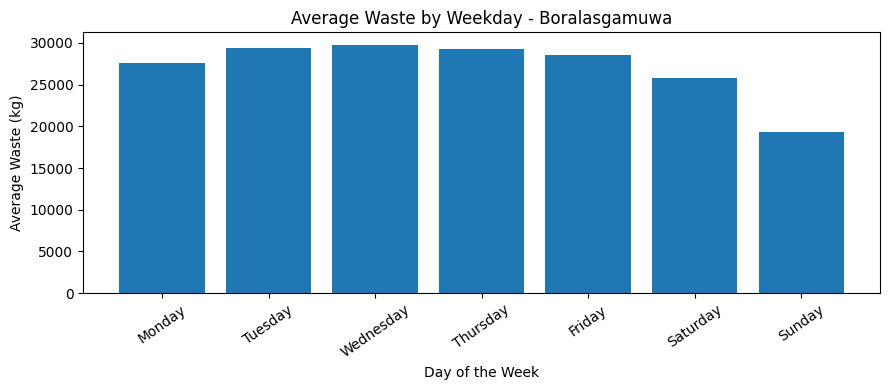

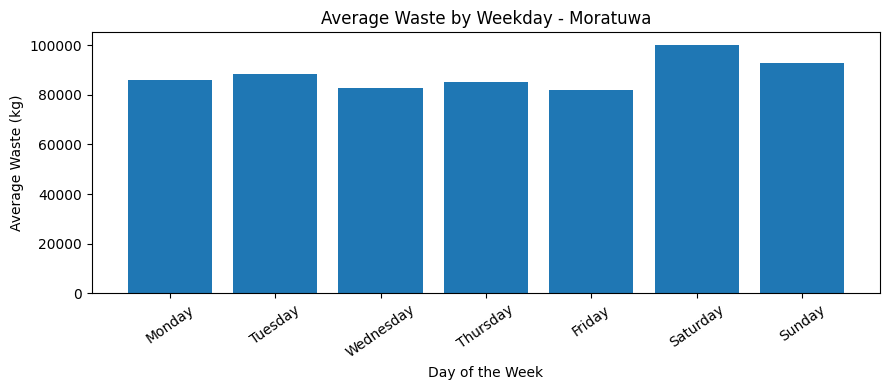

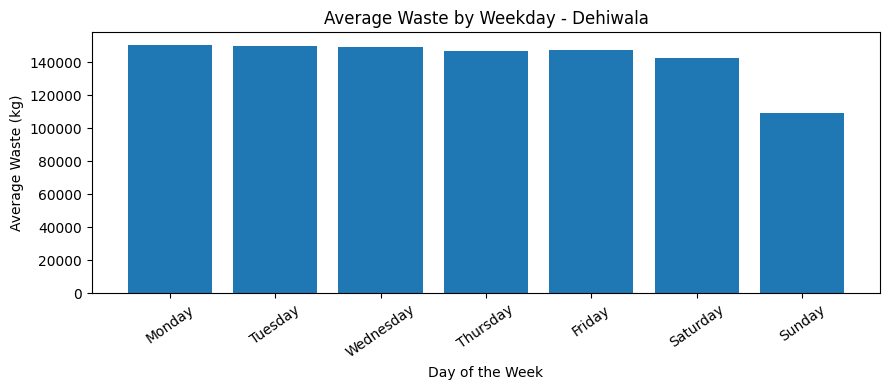

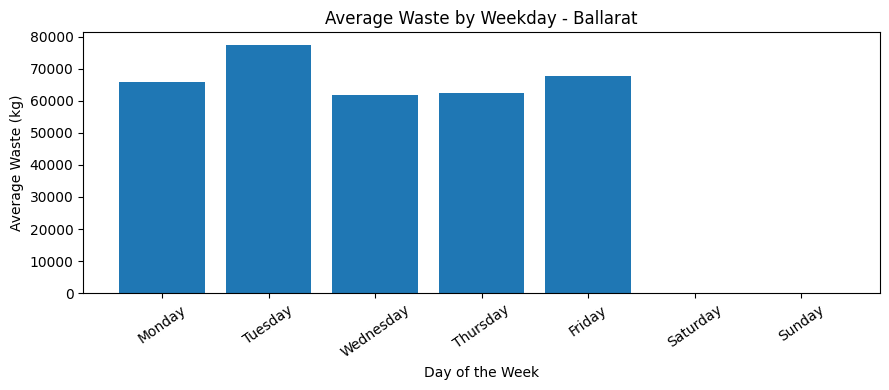

In [5]:
weekday_names = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

for name, df in datasets.items():
    temp = df.copy()
    temp["Day"] = temp["ticket_date"].dt.dayofweek

    weekly = temp.groupby("Day")["net_weight_kg"].mean()
    weekly = weekly.reindex(range(7))

    plt.figure(figsize=(9, 4))
    plt.bar(weekday_names, weekly.values)

    plt.title(f"Average Waste by Weekday - {name}")
    plt.xlabel("Day of the Week")
    plt.ylabel("Average Waste (kg)")
    plt.xticks(rotation=35)
    plt.tight_layout()
    plt.show()

In [6]:
test_dates = {
    "Boralasgamuwa": "2016-05-01",
    "Moratuwa": "2017-11-01",
    "Dehiwala": "2015-02-01",
    "Ballarat": "2008-09-01",

}

train_test_data = {}

for name, df in datasets.items():
    series = (
        df.set_index("ticket_date")["net_weight_kg"]
        .sort_index()
    )

    if series.index.duplicated().any():
        raise ValueError(f"{name} contains duplicate dates.")

    split_date = pd.Timestamp(test_dates[name])

    train = series[series.index < split_date]
    test = series[series.index >= split_date]

    if train.empty or test.empty:
        raise ValueError(
            f"{name} has an empty training or test set. "
            "Check the dataset date range."
        )

    train_test_data[name] = (train, test)

    print(
        f"{name}: Training = {len(train)} days, "
        f"Testing = {len(test)} days"
    )

Boralasgamuwa: Training = 1582 days, Testing = 975 days
Moratuwa: Training = 1035 days, Testing = 426 days
Dehiwala: Training = 1127 days, Testing = 334 days
Ballarat: Training = 2800 days, Testing = 1217 days


In [7]:
%pip install -q lightgbm prophet pmdarima

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 12.0 MB/s eta 0:00:00


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error

from lightgbm import LGBMRegressor
from pmdarima import auto_arima
from prophet import Prophet

LAGS = [1, 2, 3, 7, 14, 28]


def forecast_ml(train, test, model_name):
    # Prepare training features using previous observations
    train_df = pd.DataFrame({"y": train})

    for lag in LAGS:
        train_df[f"lag_{lag}"] = train.shift(lag)

    train_df = train_df.dropna()

    X_train = train_df.drop(columns="y")
    y_train = train_df["y"]

    # Select model
    if model_name == "Linear Regression":
        model = LinearRegression()

    elif model_name == "Random Forest":
        model = RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )

    elif model_name == "LightGBM":
        model = LGBMRegressor(
            n_estimators=100,
            learning_rate=0.05,
            random_state=42,
            verbosity=-1
        )

    model.fit(X_train, y_train)

    # Predict one day at a time
    history = train.tolist()
    predictions = []

    for _ in range(len(test)):
        features = {
            f"lag_{lag}": history[-lag]
            for lag in LAGS
        }

        X_next = pd.DataFrame([features])
        prediction = float(model.predict(X_next)[0])

        predictions.append(prediction)
        history.append(prediction)

    return pd.Series(predictions, index=test.index)

Auto Arima

In [9]:
def forecast_arima(train, test):
    model = auto_arima(
        train,
        seasonal=False,
        stepwise=True,
        suppress_warnings=True,
        error_action="ignore"
    )

    predictions = model.predict(n_periods=len(test))

    return pd.Series(
        np.asarray(predictions),
        index=test.index
    )

Prophet

In [10]:
def forecast_prophet(train, test):
    train_df = pd.DataFrame({
        "ds": train.index,
        "y": train.values
    })

    model = Prophet(
        weekly_seasonality=True,
        yearly_seasonality=True,
        daily_seasonality=False
    )

    model.fit(train_df)

    future = pd.DataFrame({"ds": test.index})
    forecast = model.predict(future)

    return pd.Series(
        forecast["yhat"].to_numpy(),
        index=test.index
    )

In [11]:
def calculate_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual = actual[valid]
    predicted = predicted[valid]

    if len(actual) == 0:
        raise ValueError("No valid predictions to evaluate.")

    rmse = np.sqrt(mean_squared_error(actual, predicted))
    mae = mean_absolute_error(actual, predicted)

    nonzero = actual != 0

    if nonzero.any():
        mape = np.mean(
            np.abs(
                (actual[nonzero] - predicted[nonzero])
                / actual[nonzero]
            )
        ) * 100
    else:
        mape = np.nan

    return {
        "RMSE": rmse,
        "MAE": mae,
        "MAPE (%)": mape
    }

In [12]:
all_results = []
prediction_results = {}

for dataset_name, (train, test) in train_test_data.items():

    models = {
        "Linear Regression": lambda: forecast_ml(
            train, test, "Linear Regression"
        ),
        "Random Forest": lambda: forecast_ml(
            train, test, "Random Forest"
        ),
        "LightGBM": lambda: forecast_ml(
            train, test, "LightGBM"
        ),
        "AutoARIMA": lambda: forecast_arima(train, test),
        "Prophet": lambda: forecast_prophet(train, test)
    }

    for model_name, forecast_function in models.items():
        try:
            predictions = forecast_function()

            metrics = calculate_metrics(test, predictions)

            all_results.append({
                "Dataset": dataset_name,
                "Model": model_name,
                **metrics
            })

            prediction_results[(dataset_name, model_name)] = pd.DataFrame({
                "Actual": test,
                "Predicted": predictions
            })

            print(f"Completed: {dataset_name} - {model_name}")

        except Exception as error:
            print(
                f"Failed: {dataset_name} - {model_name}: {error}"
            )

results_df = pd.DataFrame(all_results)

display(
    results_df.sort_values(
        ["Dataset", "RMSE"]
    ).round(3)
)

Completed: Boralasgamuwa - Linear Regression
Completed: Boralasgamuwa - Random Forest
Completed: Boralasgamuwa - LightGBM
Completed: Boralasgamuwa - AutoARIMA
Completed: Boralasgamuwa - Prophet
Completed: Moratuwa - Linear Regression
Completed: Moratuwa - Random Forest
Completed: Moratuwa - LightGBM
Completed: Moratuwa - AutoARIMA
Completed: Moratuwa - Prophet
Completed: Dehiwala - Linear Regression
Completed: Dehiwala - Random Forest
Completed: Dehiwala - LightGBM
Completed: Dehiwala - AutoARIMA
Completed: Dehiwala - Prophet
Completed: Ballarat - Linear Regression
Completed: Ballarat - Random Forest
Completed: Ballarat - LightGBM
Completed: Ballarat - AutoARIMA
Completed: Ballarat - Prophet


,Dataset,Model,RMSE,MAE,MAPE (%)
19,Ballarat,Prophet,7744.698,6243.086,8.549
15,Ballarat,Linear Regression,13055.774,10563.145,14.482
16,Ballarat,Random Forest,13181.189,9365.399,16.955
17,Ballarat,LightGBM,32516.910,27797.355,23.907
18,Ballarat,AutoARIMA,43318.480,41529.199,63.824
0,Boralasgamuwa,Linear Regression,8345.476,6421.711,31.969
2,Boralasgamuwa,LightGBM,8378.843,6437.645,32.072
1,Boralasgamuwa,Random Forest,8504.241,6650.568,31.758
4,Boralasgamuwa,Prophet,9485.551,7416.465,40.088
3,Boralasgamuwa,AutoARIMA,14743.869,11771.507,62.806


In [13]:
best_models = (
    results_df.dropna(subset=["RMSE"])
    .loc[
        results_df.dropna(subset=["RMSE"])
        .groupby("Dataset")["RMSE"].idxmin()
    ]
    .sort_values("Dataset")
    .reset_index(drop=True)
)

display(best_models.round(3))

,Dataset,Model,RMSE,MAE,MAPE (%)
0,Ballarat,Prophet,7744.698,6243.086,8.549
1,Boralasgamuwa,Linear Regression,8345.476,6421.711,31.969
2,Dehiwala,Prophet,39832.286,27770.758,36.249
3,Moratuwa,Prophet,23393.877,17330.184,37.802


In [14]:
output_folder = "/content/forecast_results"
os.makedirs(output_folder, exist_ok=True)

results_df.to_csv(
    f"{output_folder}/all_model_results.csv",
    index=False
)

best_models.to_csv(
    f"{output_folder}/best_models_by_dataset.csv",
    index=False
)

for (dataset_name, model_name), predictions in prediction_results.items():
    filename = f"{dataset_name}_{model_name.replace(' ', '_')}.csv"
    predictions.to_csv(
        os.path.join(output_folder, filename),
        index_label="ticket_date"
    )

print("Evaluation results and predictions saved.")

Evaluation results and predictions saved.
